<a href="https://colab.research.google.com/github/RizkyFirdiansyah/PCVK_Ganjil2026/blob/main/Week09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

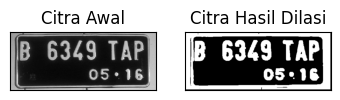

In [ ]:
# Dilasi tanpa library
def dilasi_citra(F,w):
  p,q = F.shape
  imgD = np.zeros((p,q), dtype=np.uint8)

  SED = np.ones((w,w), dtype=np.uint8)
  constant1 = (w-1)//2

  for i in range(constant1,p-constant1):
    for j in range(constant1,q-constant1):
      temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product = temp*SED
      imgD[i,j] = np.max(product)
  return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


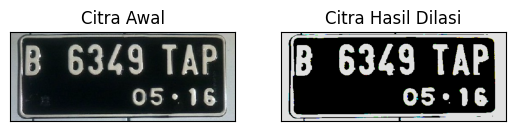

In [ ]:
# Dilasi menggunakan library morphology OpenCV
img = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg')
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv2.dilate(thresh,kernel,iterations = 1)
print(kernel)

plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

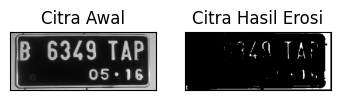

In [ ]:
# Erosi tanpa library
def erosi_citra(F,k):
  m,n = F.shape

  SE = np.ones((k,k), dtype=np.uint8)
  constant = (k-1)//2

  imgE = np.zeros((m,n), dtype=np.uint8)

  for i in range(constant,m-constant):
    for j in range(constant,n-constant):
      temp = F[i-constant:i+constant+1, j-constant:j+constant+1]
      product = temp*SE
      imgE[i,j] = np.min(product)
  return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 255, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

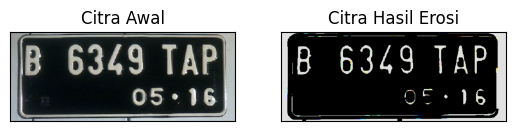

In [ ]:
# Erosi menggunakan library morphology openCV
img = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg')

kernel = np.ones((5,5),np.uint8)
erosion = cv2.erode(thresh,kernel,iterations = 1)

plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

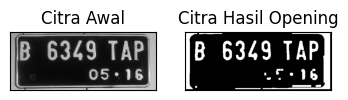

In [ ]:
# Opening tanpa library
img_o = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
reto, thresho = cv2.threshold(img_o, 127, 255, cv2.THRESH_BINARY)
k = 7
imgO= dilasi_citra(erosi_citra(thresho,k),k)

plt.subplot(131),plt.imshow(img_o,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgO,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

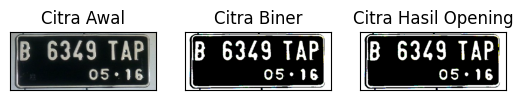

In [ ]:
# Opening menggunakan library morphology openCV
img = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg')
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((3,3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(openn,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

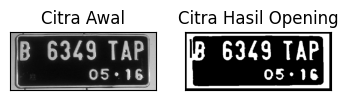

In [ ]:
# Closing tanpa library
img_c = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
retc, threshc = cv2.threshold(img_c, 127, 255, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc,k),k)

plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgC,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

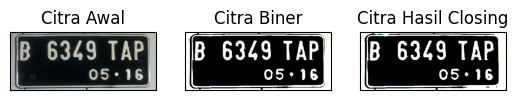

In [ ]:
# Closing menggunakan library morphology openCV
img = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg')
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((3,3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(closs,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 3


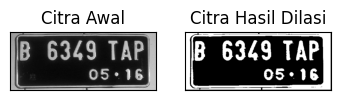

In [ ]:
# Dilasi dengan structuring element berbentuk cross 3x3 dan 5x5

# 3x3
def dilasi_citra(F,w):
  p,q = F.shape
  imgD = np.zeros((p,q), dtype=np.uint8)

  SED = np.array([[0,1,0],[1,1,1],[0,1,0]], dtype=np.uint8)
  constant1 = (w-1)//2

  for i in range(constant1,p-constant1):
    for j in range(constant1,q-constant1):
      temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product = temp*SED
      imgD[i,j] = np.max(product)
  return imgD

print('SED = Cross 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 5


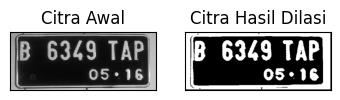

In [ ]:
# 2x5
def dilasi_citra(F,w):
  p,q = F.shape
  imgD = np.zeros((p,q), dtype=np.uint8)

  SED = np.array([[0,0,1,0,0],[0,0,1,0,0],[1,1,1,1,1],[0,0,1,0,0],[0,0,1,0,0]], dtype=np.uint8)
  constant1 = (w-1)//2

  for i in range(constant1,p-constant1):
    for j in range(constant1,q-constant1):
      temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product = temp*SED
      imgD[i,j] = np.max(product)
  return imgD

print('SED = Cross 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Circle 3


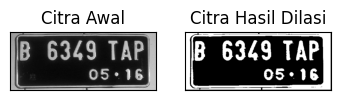

Circle = 5


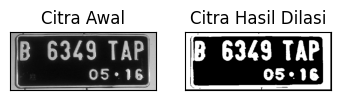

In [ ]:
# Dilasi dengan structuring element berbentuk circular 3x3 dan 5x5
# 3x3
def dilasi_citra(F,w):
  p,q = F.shape
  imgD = np.zeros((p,q), dtype=np.uint8)

  SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
  constant1 = (w-1)//2

  for i in range(constant1,p-constant1):
    for j in range(constant1,q-constant1):
      temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product = temp*SED
      imgD[i,j] = np.max(product)
  return imgD

print('SED = Circle 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

print('Circle = 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Rectangle 3x5


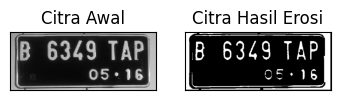

SED = Rectangle 5x7


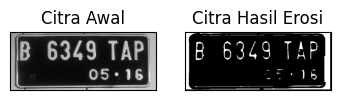

In [ ]:
# Erosi dengan structuring element berbentuk Rectangle 3x5 dan 5x7
# 3x5
def erosi_citra(F,p,l):
  m,n = F.shape

  SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l))
  constant1 = (l-1)//2
  constant2 = (p-1)//2

  imgE = np.zeros((m,n), dtype=np.uint8)

  for i in range(constant1,m-constant1):
    for j in range(constant2,n-constant2):
      temp = F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product = temp*SE
      imgE[i,j] = np.min(product)
  return imgE

print('SED = Rectangle 3x5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE = erosi_citra(thresh1,p,l)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SED = Rectangle 5x7')
img_e = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 7
l = 5
imgE = erosi_citra(thresh1,p,l)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Line Vertikal 3


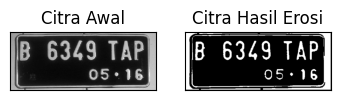

SED = Line Vertikal 5


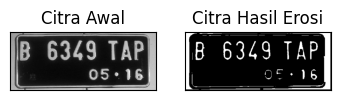

In [ ]:
# Erosi dengan structuring element berbentuk Line Vertikal 3 dan 5
# 3
def erosi_citra(F,k):
  m,n = F.shape

  SE = cv2.getStructuringElement(cv2.MORPH_RECT,(1,k))
  constant = (k-1)//2

  imgE = np.zeros((m,n), dtype=np.uint8)

  for i in range(constant,m-constant):
    for j in range(constant,n-constant):
      temp = F[i-constant:i+constant+1, j-constant:j+constant+1]
      product = temp*SE
      imgE[i,j] = np.min(product)
  return imgE

print('SED = Line Vertikal 3')
img_e = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SED = Line Vertikal 5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK2026/platNomor.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

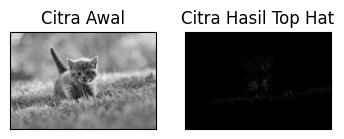

In [ ]:
# Top Hat
filterSize = (3,3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/PCVK2026/kitten.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
plt.title('Citra Hasil Top Hat'), plt.xticks([]), plt.yticks([])
plt.show()

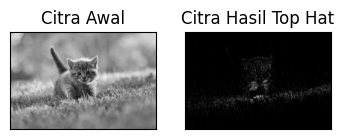

In [ ]:
# Black Hat
filterSize = (3,3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/PCVK2026/kitten.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13,5))
blackhat_img = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat_img,cmap = 'gray')
plt.title('Citra Hasil Top Hat'), plt.xticks([]), plt.yticks([])
plt.show()

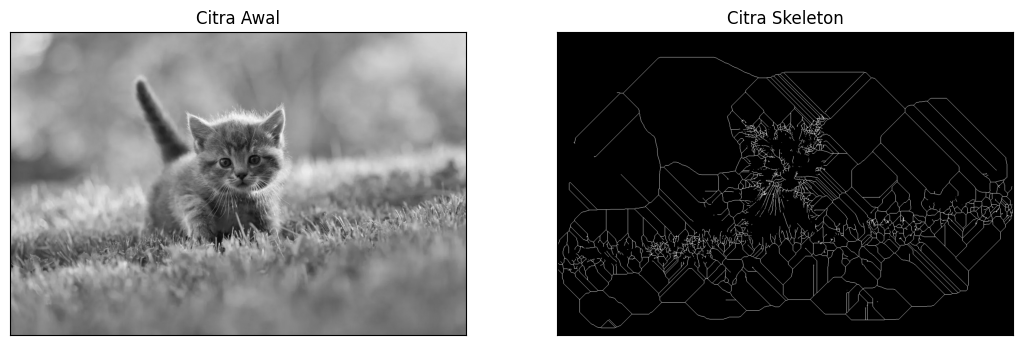

In [19]:
# Skeleton
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = cv2.imread('/content/drive/MyDrive/PCVK2026/kitten.jpg',0)

binary = img > filters.threshold_triangle(img)

binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(20,20))

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(skeleton,cmap = 'gray')
plt.title('Citra Skeleton'), plt.xticks([]), plt.yticks([])
plt.savefig("binary and bin_skeleton.png")
plt.show()